# Topic discovery | Latent Dirichlet Allocation

Prepare a bag-of-words representation and fit LDA models from **2 to 15 topics** with the original fixed seed. Compare the models using `c_v` coherence, then read the highest-scoring model's leading terms.

Topics are statistical word distributions. Their names and practical meaning require examination of representative documents; no topic-quality results are claimed here because the uploaded notebooks have no saved outputs.


## Load the topic-modeling environment

Import NLP, gensim and plotting dependencies, and prepare the NLTK resources consumed by the original lemmatization pipeline.


In [1]:
# Load the required libraries and NLTK resources for topic discovery.

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from collections import Counter
from scipy.sparse import hstack, csr_matrix
from sklearn.cluster import HDBSCAN

from sklearn.cluster import KMeans
from sklearn.metrics import make_scorer, silhouette_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import GridSearchCV
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from nltk.corpus import stopwords
from nltk import pos_tag
from spacy.lang.en.stop_words import STOP_WORDS as SPACY_STOP_WORDS

from mpl_toolkits.mplot3d import Axes3D 

import gensim
from gensim.models import Word2Vec
from gensim import corpora
from gensim.models import LsiModel, LdaModel
from gensim.models.coherencemodel import CoherenceModel

import warnings
warnings.filterwarnings('ignore')

nltk.data.path.append("./data")
nltk.download('punkt', download_dir="./data")
nltk.download("punkt_tab", download_dir="./data")
nltk.download("averaged_perceptron_tagger", download_dir="./data")
nltk.download("averaged_perceptron_tagger_eng", download_dir="./data")
nltk.download('stopwords', download_dir="./data")
nltk.download('wordnet', download_dir="./data")



[nltk_data] Downloading package punkt to ./data...
[nltk_data] Refusing to install into
[nltk_data]     '/home/mouelhis/Private/github/new_dsac/twm/data': it
[nltk_data]     is writable by, or owned by, another account, so a
[nltk_data]     file swapped in during the install would be installed
[nltk_data]     as trusted data. Make it private to its owner (chmod
[nltk_data]     go-w).
[nltk_data] Downloading package punkt_tab to ./data...
[nltk_data] Refusing to install into
[nltk_data]     '/home/mouelhis/Private/github/new_dsac/twm/data': it
[nltk_data]     is writable by, or owned by, another account, so a
[nltk_data]     file swapped in during the install would be installed
[nltk_data]     as trusted data. Make it private to its owner (chmod
[nltk_data]     go-w).
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     ./data...
[nltk_data] Refusing to install into
[nltk_data]     '/home/mouelhis/Private/github/new_dsac/twm/data': it
[nltk_data]     is writable

False

## Load the stored article snapshot

Read the renamed CSV, remove missing article bodies, and combine titles with body text as in the original pipeline.


In [2]:
# Read the corpus snapshot and retain only records with available article text.



print("Loading data...")
try:
    df = pd.read_csv("./data/youth_information_articles.csv", encoding='utf-8-sig')

    
    df['article_title'] = df['article_title'].fillna('').astype(str)

    
    
    df = df[df['article_body'] != 'N/A']
    df = df.dropna(subset=['article_body'])

    
    
    df['article_body'] = df['article_title'] + " " + df['article_body']

    print(f"Successfully loaded {len(df)} articles.")
except FileNotFoundError:
    print(f"Error: File not found at './data/youth_information_articles.csv'. Please run the scraper first.")
    exit()

Loading data...
Successfully loaded 2973 articles.


**How to interpret this step.** This analysis uses the supplied article snapshot, not a newly collected crawl.


## Build a dictionary and bag-of-words corpus

Apply POS-aware lemmatization and the existing stopword rules; discard empty documents, remove extremely rare and frequent dictionary terms, and construct the gensim corpus.


In [4]:

from pathlib import Path
import nltk

# Configure a private directory for NLTK language resources.
nltk_data_dir = Path.home() / "nltk_data"
nltk_data_dir.mkdir(parents=True, exist_ok=True)
nltk_data_dir.chmod(0o700)

# Register the directory as the preferred resource location.
if str(nltk_data_dir) in nltk.data.path:
    nltk.data.path.remove(str(nltk_data_dir))

nltk.data.path.insert(0, str(nltk_data_dir))

# Install the corpora and tagging models required by
# the article preprocessing and LDA workflow.
resources = [
    "stopwords",
    "wordnet",
    "omw-1.4",
    "averaged_perceptron_tagger_eng"
]

for resource in resources:
    print(f"Installing: {resource}")
    nltk.download(
        resource,
        download_dir=str(nltk_data_dir),
        quiet=True,
        raise_on_error=True
    )

print("NLTK resources are ready.")


Installing: stopwords
Installing: wordnet
Installing: omw-1.4
Installing: averaged_perceptron_tagger_eng
NLTK resources are ready.


In [5]:
# Normalize article tokens, form the dictionary, and build a bag-of-words representation.


stop_words = set(stopwords.words('english'))


domain_stopwords = [
    
    'spunout', 'spun', 'out', 'ie', 'ireland', 'irish', 'www', 'http', 'https', 'com', 
    'copyright', 'privacy', 'policy', 'terms', 'conditions', 'login', 'sign', 'register',
    
    
    'page', 'section', 'footer', 'header', 'sidebar', 'widget', 'nav', 'advertisement', 'ad',
    'promo', 'cookie', 'script', 'javascript', 'css', 'html', 'body', 'main', 'published', 'updated',
    'author', 'post', 'article', 'url', 'permalink',
    
    
    'day', 'new', 'good', 'bad',
    'check', 'try', 'keep',
    'like', 'just', 'get', 'also', 'would', 'could', 'one', 'make', 'use', 'way', 'well', 
    'time', 'know', 'need', 'really', 'thing', 'think', 'much', 'even', 'still', 'another', 
    'every', 'go', 'want', 'take', 'find', 'look', 'come', 'year', 'old', 'may', 'might',
    
    
    'click', 'read', 'link', 'menu', 'comment', 'reply',
    
    
    'u', 'ur', 'im', 'dont', 'cant', 'wont', 'oh', 'ok', 'please', 'thanks', 'thank', 'yes', 'no'
]


all_stopwords = stop_words.union(domain_stopwords)



lemmatizer = WordNetLemmatizer()

def wordnet_tag_from_treebank(treebank_tag):
    """Convert Penn Treebank tags into the part-of-speech codes used by WordNet."""
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN



def normalize_article_text(text):
    """
    Applies regex, lemmatization, and stopword removal.
    """
    
    text = str(text).lower()
    
    
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'<.*?>', ' ', text)
    
    
    text = re.sub(r'[\_\-\.]{1,}', ' ', text)
    text = re.sub(r'[/\\]', ' ', text)

    
    text = re.sub(r"\'", "", text)
    
    
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    
    text = re.sub(r'\s+[a-z]\s+', ' ', text)
    
    
    words = text.split()
    
    
    
    tagged_words = pos_tag(words)
    lemmatized_words = []
    
    for word, tag in tagged_words:
        wn_tag = wordnet_tag_from_treebank(tag)
        lemma = lemmatizer.lemmatize(word, pos=wn_tag)
        lemmatized_words.append(lemma)
    
    
    
    filtered_words = [word for word in lemmatized_words if word not in all_stopwords and len(word) > 2]
    
    return filtered_words



print(f"Cleaning {len(df)} documents (this may take a moment due to POS tagging)...")



texts = df['article_body'].apply(normalize_article_text).tolist()


texts = [t for t in texts if len(t) > 0]
print(f"Valid documents after cleaning: {len(texts)}")





dictionary = corpora.Dictionary(texts)






dictionary.filter_extremes(no_below=5, no_above=0.4)

print(f"Dictionary size after filtering: {len(dictionary)} unique tokens.")


doc_term_matrix = [dictionary.doc2bow(text) for text in texts]

print("Preprocessing complete. Ready for LDA.")

Cleaning 2973 documents (this may take a moment due to POS tagging)...
Valid documents after cleaning: 2973
Dictionary size after filtering: 7931 unique tokens.
Preprocessing complete. Ready for LDA.


**How to interpret this step.** Dictionary filtering changes which words LDA can model; excluded tokens cannot appear in the learned topic descriptors.


## Compare topic counts with coherence

Fit LDA over the original two-to-fifteen-topic range and record `c_v` coherence for each candidate using the existing model settings.


In [6]:
# Fit each LDA candidate and record its coherence using unchanged hyperparameters.


coher_vals2 = []
lda_models = []
limit = 15; start=2; step=1  

for num_topics in range(start, limit+1, step):
    
    lda_model = LdaModel(
        corpus=doc_term_matrix,
        id2word=dictionary,
        num_topics=num_topics,
        chunksize=2000,
        passes=30,
        iterations=500,
        random_state=43,
        update_every=1, 
        alpha='auto',   
        eta='auto'      
    )
    
    lda_models.append(lda_model)
    
    
    coherence_model = CoherenceModel(
        model=lda_model, 
        texts=texts, 
        dictionary=dictionary, 
        coherence='c_v'
    )
    coher_vals2.append(coherence_model.get_coherence())
    print(f"Topics: {num_topics} | Coherence Score: {coher_vals2[-1]:.4f}")

Topics: 2 | Coherence Score: 0.3288
Topics: 3 | Coherence Score: 0.4437
Topics: 4 | Coherence Score: 0.4942
Topics: 5 | Coherence Score: 0.5338
Topics: 6 | Coherence Score: 0.5200
Topics: 7 | Coherence Score: 0.5085
Topics: 8 | Coherence Score: 0.5105
Topics: 9 | Coherence Score: 0.5160
Topics: 10 | Coherence Score: 0.5404
Topics: 11 | Coherence Score: 0.5803
Topics: 12 | Coherence Score: 0.5781
Topics: 13 | Coherence Score: 0.5749
Topics: 14 | Coherence Score: 0.5755
Topics: 15 | Coherence Score: 0.5885


**How to interpret this step.** Coherence measures how frequently topic words co-occur in related contexts. The maximum is a useful heuristic, not a guarantee of semantic quality.


## Plot coherence against topic count

Save the coherence curve in `images/` for visual comparison of candidate topic counts.



Plot successfully saved to: ./images/optimal_number_of_topics.png


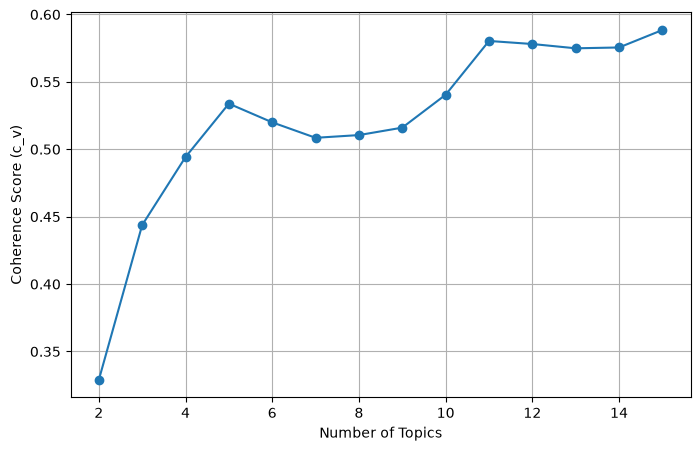

In [7]:
# Visualize coherence values to compare the candidate topic counts.

import os

x = range(start, limit+1, step)
plt.figure(figsize=(8,5))
plt.plot(x, coher_vals2, marker='o')
plt.xlabel("Number of Topics")
plt.ylabel("Coherence Score (c_v)")

plt.grid(True)

folder_name = "./images/"
file_name = "optimal_number_of_topics.png"


if not os.path.exists(folder_name):
    os.makedirs(folder_name)


full_path = os.path.join(folder_name, file_name)

plt.savefig(full_path, dpi=300, bbox_inches='tight')

print(f"\nPlot successfully saved to: {full_path}")
plt.show()

**How to interpret this step.** Look for a stable region as well as the maximum: very small score differences may not justify additional topics.


## Select the highest-coherence run

Locate the topic count with the greatest recorded coherence and retain its corresponding model index.


In [8]:
# Identify the model index with the highest recorded coherence.


print("\nApplying Best Model ---")


optimal_num_topics_index = coher_vals2.index(max(coher_vals2))
optimal_num_topics = x[optimal_num_topics_index]
print(f"Optimal Number of Topics: {optimal_num_topics}")


Applying Best Model ---
Optimal Number of Topics: 15


**How to interpret this step.** The selected count is conditional on this corpus, preprocessing configuration, and the tested range.


## Review the leading topic terms

Print ten weighted terms for each topic in the selected LDA model.


In [9]:
# Review the most probable words in each discovered topic.


best_lda_model = lda_models[optimal_num_topics_index]



print(f"\nTop 10 words for each of the {optimal_num_topics} topics:")
topics = best_lda_model.print_topics(num_words=10)
for topic_id, topic_content in topics:
    print(f"Topic {topic_id}: {topic_content}")


Top 10 words for each of the 15 topics:
Topic 0: 0.064*"sex" + 0.031*"sexual" + 0.019*"partner" + 0.018*"sti" + 0.013*"consent" + 0.011*"condom" + 0.010*"stis" + 0.009*"symptom" + 0.008*"cause" + 0.008*"period"
Topic 1: 0.027*"mental" + 0.013*"disorder" + 0.010*"eat" + 0.010*"self" + 0.009*"stress" + 0.009*"anxiety" + 0.009*"therapy" + 0.008*"symptom" + 0.008*"social" + 0.008*"condition"
Topic 2: 0.022*"food" + 0.012*"eat" + 0.011*"water" + 0.010*"buy" + 0.009*"clothes" + 0.009*"minute" + 0.008*"add" + 0.008*"healthy" + 0.008*"meal" + 0.007*"shop"
Topic 3: 0.019*"european" + 0.016*"country" + 0.012*"right" + 0.010*"covid" + 0.010*"travel" + 0.009*"state" + 0.008*"government" + 0.007*"europe" + 0.006*"minister" + 0.006*"member"
Topic 4: 0.024*"test" + 0.020*"hiv" + 0.017*"abortion" + 0.014*"covid" + 0.013*"vaccine" + 0.013*"risk" + 0.012*"cancer" + 0.011*"symptom" + 0.011*"contact" + 0.011*"clinic"
Topic 5: 0.009*"woman" + 0.008*"smoke" + 0.007*"world" + 0.007*"racism" + 0.007*"medium"

**How to interpret this step.** Assign short human-readable descriptions only after inspecting representative articles; topic words alone can be ambiguous or overlapping.
